# Estée Lauder: Digital Feature Rollout Analysis
## Progressive analysis through Milestone 5

**Project:** Measuring Customer Delight  
**Prepared by:** Gaurvendra Pratap Singh Pundhir  
**Analysis:** United States treatment market, Canada comparison market

This notebook brings together the analysis completed over the first five milestones. It starts with a review of the data and the original before-and-after comparisons, then moves into difference-in-differences, regression estimates, and the additional checks requested for Milestone 5.

The earlier results are retained to make the progression easy to follow. All regression estimates used for the current submission are reported with HC3 robust standard errors, consistent with the challenge advisor's instructions.

For Milestone 5, the team divided the work as follows: I was assigned the baseline and anticipation-adjusted fixed-effects models (A and B). The anticipation assessment, fully adjusted Model C, and overall interpretation were assigned to other team members. The complete three-model analysis is included here for comparison and continuity.


## Conceptual build-up

The business question is:

> Did the Scent Advisor increase U.S. revenue per session, or would U.S. revenue have increased anyway?

The challenge is the counterfactual. We never observe what the U.S. would have done after launch **without** the digital feature. So we use an untreated market as a comparison.

From the earlier EDA/control-selection work, **Canada** was selected as the main control market because it was the strongest pre-launch comparison for the U.S. We do not redo that selection here; we reuse it.

```text
EDA / control selection
        ↓
Naive U.S. before-after
        ↓
Manual 2x2 Difference-in-Differences
        ↓
Simple regression DiD
        ↓
Two-way fixed-effects DiD
        ↓
Slide-ready business interpretation
```


In [1]:
# Core imports
from pathlib import Path
from datetime import datetime, timezone
import json
import warnings

import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)


In [2]:
# Locate repo root. This works if you run from repo root or from notebooks/simple_did/.
def find_repo_root(start: Path | None = None) -> Path:
    start = Path.cwd() if start is None else Path(start)
    for p in [start, *start.parents]:
        if (p / "data" / "market_week_data.csv").exists():
            return p
    raise FileNotFoundError(
        "Could not find repo root containing data/market_week_data.csv. "
        "Run this notebook from the repo root or place it inside the repo."
    )

ROOT = find_repo_root()
DATA_PATH = ROOT / "data" / "market_week_data.csv"
RESULTS_DIR = ROOT / "results"
FIGURES_DIR = ROOT / "figures"
RESULTS_DIR.mkdir(exist_ok=True)
FIGURES_DIR.mkdir(exist_ok=True)

ROOT, DATA_PATH


(PosixPath('/mnt/data/ELC_Progressive_M1_to_M5'),
 PosixPath('/mnt/data/ELC_Progressive_M1_to_M5/data/market_week_data.csv'))

In [3]:
# Reuse the project helper module if available, as requested in the GitHub issues.
import sys
SRC_PATH = ROOT / "src"
if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

try:
    import simple_did as sd
    HAS_SD = True
    print("Loaded src/simple_did.py helpers successfully.")
except Exception as e:
    HAS_SD = False
    print("Could not import src/simple_did.py. Using notebook fallbacks instead.")
    print("Import error:", repr(e))


Could not import src/simple_did.py. Using notebook fallbacks instead.
Import error: ModuleNotFoundError("No module named 'simple_did'")


## 1. Load and validate the panel data

The dataset is a weekly market panel. Each row is one market-week observation.

The key fields we need are:

- `market`
- `week_start`
- `revenue_per_session`
- `pilot_market`
- `post_launch`
- `digital_feature_available`

The outcome is **revenue per session**.


In [4]:
df = pd.read_csv(DATA_PATH)
df["week_start"] = pd.to_datetime(df["week_start"])

# If revenue_per_session is missing, recalculate it from revenue / sessions.
if "revenue_per_session" not in df.columns:
    df["revenue_per_session"] = df["fragrance_revenue"] / df["sessions"]

if {"fragrance_revenue", "sessions"}.issubset(df.columns):
    df["revenue_per_session_recalc"] = df["fragrance_revenue"] / df["sessions"]
else:
    df["revenue_per_session_recalc"] = df["revenue_per_session"]

METRIC = "revenue_per_session"
TREATED = "United States"
CONTROL = "Canada"
AUTHOR = "@gaurvsingh095"

print("Shape:", df.shape)
print("Markets:", sorted(df["market"].unique()))
print("Date range:", df["week_start"].min().date(), "to", df["week_start"].max().date())
print("Rows per market:")
display(df.groupby("market")["week_start"].nunique().rename("n_weeks").to_frame())
display(df.head())


Shape: (728, 17)
Markets: ['Australia', 'Canada', 'France', 'Germany', 'Japan', 'United Kingdom', 'United States']
Date range: 2025-01-06 to 2026-12-28
Rows per market:


,n_weeks
market,
Australia,104
Canada,104
France,104
Germany,104
Japan,104
United Kingdom,104
United States,104


,market,week_index,week_start,sessions,fragrance_orders,fragrance_revenue,conversion_rate,average_order_value,revenue_per_session,paid_media_index,promo_intensity,new_visitor_share,pilot_market,post_launch,digital_feature_available,weeks_from_launch,revenue_per_session_recalc
0,Australia,0,2025-01-06,69314,1870,147050.31,0.026979,78.64,2.1215,96.81,0.2081,0.3308,0,0,0,-65,2.121510
1,Australia,1,2025-01-13,71010,2011,159108.26,0.028320,79.12,2.2406,100.78,0.2142,0.3870,0,0,0,-64,2.240646
2,Australia,2,2025-01-20,71268,1954,150249.86,0.027418,76.89,2.1082,89.21,0.2005,0.3705,0,0,0,-63,2.108237
3,Australia,3,2025-01-27,67993,1632,128219.61,0.024002,78.57,1.8858,104.77,0.2123,0.3519,0,0,0,-62,1.885777
4,Australia,4,2025-02-03,68280,1952,161268.21,0.028588,82.62,2.3619,101.49,0.1982,0.3558,0,0,0,-61,2.361866


In [5]:
validation = {
    "rows": int(len(df)),
    "columns": int(df.shape[1]),
    "markets": int(df["market"].nunique()),
    "min_week": str(df["week_start"].min().date()),
    "max_week": str(df["week_start"].max().date()),
    "missing_values_total": int(df.isna().sum().sum()),
    "duplicate_market_weeks": int(df.duplicated(["market", "week_start"]).sum()),
}
validation


{'rows': 728,
 'columns': 17,
 'markets': 7,
 'min_week': '2025-01-06',
 'max_week': '2026-12-28',
 'missing_values_total': 0,
 'duplicate_market_weeks': 0}

## 2. Prior build-up: treatment, post period, and control market

Treatment is defined as the U.S. after the digital feature becomes available.

```text
Treated market = United States
Control market = Canada
Treatment variable = digital_feature_available
```

The earlier work selected Canada as the control, so this notebook uses **U.S. + Canada only** for the regression DiD tasks.


In [6]:
required_cols = ["market", "week_start", METRIC, "pilot_market", "post_launch", "digital_feature_available"]
missing = [c for c in required_cols if c not in df.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

us_ca = df[df["market"].isin([TREATED, CONTROL])].copy()
us_ca = us_ca.sort_values(["market", "week_start"]).reset_index(drop=True)

print("US + Canada shape:", us_ca.shape)
print(us_ca.groupby("market")["week_start"].agg(["min", "max", "nunique"]))

launch_week = df.loc[df["digital_feature_available"].eq(1), "week_start"].min()
print("Launch week:", launch_week.date())


US + Canada shape: (208, 17)
                     min        max  nunique
market                                      
Canada        2025-01-06 2026-12-28      104
United States 2025-01-06 2026-12-28      104
Launch week: 2026-04-06


In [7]:
prepost = (
    us_ca
    .assign(period=np.where(us_ca["post_launch"].eq(1), "post", "pre"))
    .groupby(["market", "period"], as_index=False)[METRIC]
    .mean()
    .pivot(index="market", columns="period", values=METRIC)
)
prepost["change"] = prepost["post"] - prepost["pre"]
prepost = prepost.loc[[CONTROL, TREATED]]
prepost


period,post,pre,change
market,,,
Canada,2.542264,2.446088,0.096176
United States,3.023018,2.680928,0.342090


## 3. Naive U.S. before/after estimate

The naive estimate asks:

```text
How much did U.S. revenue per session change after launch?
```

Formula:

```text
Naive = U.S. post-launch average RPS - U.S. pre-launch average RPS
```

This is useful as a baseline, but it is **not causal**, because it credits the advisor with anything else that changed around launch: seasonality, promotions, paid media, visitor mix, etc.


In [8]:
def naive_estimate(frame: pd.DataFrame, market: str = TREATED, metric: str = METRIC) -> dict:
    d = frame[frame["market"].eq(market)].copy()
    pre = d.loc[d["post_launch"].eq(0), metric].mean()
    post = d.loc[d["post_launch"].eq(1), metric].mean()
    return {
        "market": market,
        "metric": metric,
        "pre_mean": float(pre),
        "post_mean": float(post),
        "estimate": float(post - pre),
        "relative_lift": float((post - pre) / pre),
    }

naive = naive_estimate(us_ca)
naive


{'market': 'United States',
 'metric': 'revenue_per_session',
 'pre_mean': 2.680927692307692,
 'post_mean': 3.023017948717949,
 'estimate': 0.3420902564102568,
 'relative_lift': 0.12760144833141396}

## 4. Manual 2x2 Difference-in-Differences

Manual DiD subtracts Canada's baseline movement from the U.S. movement.

```text
DiD = (U.S. post - U.S. pre) - (Canada post - Canada pre)
```

This estimates the ATT under the DiD assumptions.


In [9]:
def manual_did(frame: pd.DataFrame, treated: str = TREATED, control: str = CONTROL, metric: str = METRIC) -> dict:
    def mean_market_period(market, post_flag):
        return float(frame.loc[(frame["market"].eq(market)) & (frame["post_launch"].eq(post_flag)), metric].mean())
    t_pre = mean_market_period(treated, 0)
    t_post = mean_market_period(treated, 1)
    c_pre = mean_market_period(control, 0)
    c_post = mean_market_period(control, 1)
    t_change = t_post - t_pre
    c_change = c_post - c_pre
    return {
        "treated": treated,
        "control": control,
        "metric": metric,
        "treated_pre": t_pre,
        "treated_post": t_post,
        "control_pre": c_pre,
        "control_post": c_post,
        "treated_change": t_change,
        "control_change": c_change,
        "estimate": t_change - c_change,
    }

manual = manual_did(us_ca)
manual


{'treated': 'United States',
 'control': 'Canada',
 'metric': 'revenue_per_session',
 'treated_pre': 2.680927692307692,
 'treated_post': 3.023017948717949,
 'control_pre': 2.446087692307692,
 'control_post': 2.5422641025641024,
 'treated_change': 0.3420902564102568,
 'control_change': 0.09617641025641044,
 'estimate': 0.24591384615384637}

In [10]:
prepost_summary = pd.DataFrame([
    {"market": TREATED, "pre": manual["treated_pre"], "post": manual["treated_post"], "change": manual["treated_change"]},
    {"market": CONTROL, "pre": manual["control_pre"], "post": manual["control_post"], "change": manual["control_change"]},
])
prepost_summary.to_csv(RESULTS_DIR / "m4_prepost_us_canada.csv", index=False)
prepost_summary


,market,pre,post,change
0,United States,2.680928,3.023018,0.342090
1,Canada,2.446088,2.542264,0.096176


## 5. Simple regression difference-in-differences (Issue #29)

The regression uses the pilot market indicator, the post-launch indicator, and their interaction:

```text
revenue_per_session ~ pilot_market + post_launch + pilot_market:post_launch
```

The interaction coefficient is the estimated average treatment effect on the treated (ATT). In this two-market setup, its point estimate should agree with the manual 2 by 2 calculation. Unlike the manual calculation, regression also provides a standard error, confidence interval, and p-value.

Following Luis's guidance, the current results use HC3 robust standard errors. The project's original helper used HAC, so we fit these specifications directly with `cov_type="HC3"`.


In [11]:
# The current specifications are fitted using HC3 robust standard errors.


In [12]:
import statsmodels.formula.api as smf

def fit_smf_ols_hc3(formula: str, data: pd.DataFrame):
    """
    Fit OLS regression with HC3 robust standard errors.

    HC3 adjusts the standard errors for heteroskedasticity.
    """
    return smf.ols(formula, data=data).fit(cov_type="HC3")


simple_formula = f"{METRIC} ~ pilot_market + post_launch + pilot_market:post_launch"

simple_model = fit_smf_ols_hc3(simple_formula, us_ca)

simple_term = "pilot_market:post_launch"
simple_ci = simple_model.conf_int().loc[simple_term]

simple_result = {
    "method": "simple_regression_did_hc3",
    "treated": TREATED,
    "control": CONTROL,
    "metric": METRIC,
    "window": "all_pre_vs_post",
    "estimate": float(simple_model.params[simple_term]),
    "std_err": float(simple_model.bse[simple_term]),
    "ci_low": float(simple_ci[0]),
    "ci_high": float(simple_ci[1]),
    "p_value": float(simple_model.pvalues[simple_term]),
    "issue": 29,
    "cov_type": "HC3",
}

simple_result

{'method': 'simple_regression_did_hc3',
 'treated': 'United States',
 'control': 'Canada',
 'metric': 'revenue_per_session',
 'window': 'all_pre_vs_post',
 'estimate': 0.24591384615384407,
 'std_err': 0.06456878421902709,
 'ci_low': 0.11936135455901276,
 'ci_high': 0.3724663377486754,
 'p_value': 0.00013978055555732843,
 'issue': 29,
 'cov_type': 'HC3'}

In [13]:
pd.DataFrame([simple_result])


,method,treated,control,metric,window,estimate,std_err,ci_low,ci_high,p_value,issue,cov_type
0,simple_regression_did_hc3,United States,Canada,revenue_per_session,all_pre_vs_post,0.245914,0.064569,0.119361,0.372466,0.00014,29,HC3


### Simple regression result

The treatment estimate is approximately **$0.2459 more revenue per session**. This agrees with the manual DiD result after accounting for Canada's before-and-after change.

Using HC3 robust standard errors, the 95% confidence interval is approximately **[$0.1194, $0.3725]**, and the p-value is about **0.00014**. The confidence interval does not include zero. This is a statistical result conditional on the model and does not independently establish that the feature caused the increase.


## 6. Issue #31 : Two-way fixed-effects DiD

The two-way FE model is:

```text
RPS ~ digital_feature_available + C(market) + C(week_start)
```

The coefficient on `digital_feature_available` is the estimated ATT after absorbing:

- **Market fixed effects:** stable differences between U.S. and Canada
- **Week fixed effects:** common weekly shocks like holidays, seasonality, and shared demand changes


In [14]:
# The current specifications are fitted using HC3 robust standard errors.


In [15]:
fe_formula = f"{METRIC} ~ digital_feature_available + C(market) + C(week_start)"

fe_model = fit_smf_ols_hc3(fe_formula, us_ca)

fe_term = "digital_feature_available"
fe_ci = fe_model.conf_int().loc[fe_term]

fe_result = {
    "method": "two_way_fe_did_hc3",
    "treated": TREATED,
    "control": CONTROL,
    "metric": METRIC,
    "window": "all_pre_vs_post",
    "estimate": float(fe_model.params[fe_term]),
    "std_err": float(fe_model.bse[fe_term]),
    "ci_low": float(fe_ci[0]),
    "ci_high": float(fe_ci[1]),
    "p_value": float(fe_model.pvalues[fe_term]),
    "issue": 31,
    "cov_type": "HC3",
}

fe_result

{'method': 'two_way_fe_did_hc3',
 'treated': 'United States',
 'control': 'Canada',
 'metric': 'revenue_per_session',
 'window': 'all_pre_vs_post',
 'estimate': 0.24591384615384715,
 'std_err': 0.036323044942092535,
 'ci_low': 0.174721986258516,
 'ci_high': 0.3171057060491783,
 'p_value': 1.286150807597804e-11,
 'issue': 31,
 'cov_type': 'HC3'}

In [16]:
pd.DataFrame([fe_result])


,method,treated,control,metric,window,estimate,std_err,ci_low,ci_high,p_value,issue,cov_type
0,two_way_fe_did_hc3,United States,Canada,revenue_per_session,all_pre_vs_post,0.245914,0.036323,0.174722,0.317106,1.286151e-11,31,HC3


### Two-way FE interpretation

The FE model keeps the weekly panel structure and accounts for persistent market-level differences and shared week-level shocks.

> The ATT remains about **+0.2459 revenue per session**, even after absorbing market and week fixed effects.

This makes the FE result a stronger panel-based version of the same causal story.


## 7. Compare all estimates

This table connects the full story:

1. Naive before/after
2. Manual 2x2 DiD
3. Simple regression DiD
4. Two-way FE DiD


In [17]:
# comparison = pd.DataFrame([
#     {
#         "method": "naive_before_after",
#         "estimate": naive["estimate"],
#         "ci_low": np.nan,
#         "ci_high": np.nan,
#         "p_value": np.nan,
#         "meaning": "U.S. post minus U.S. pre; descriptive baseline only",
#     },
#     {
#         "method": "manual_2x2_did",
#         "estimate": manual["estimate"],
#         "ci_low": np.nan,
#         "ci_high": np.nan,
#         "p_value": np.nan,
#         "meaning": "Subtracts Canada movement from U.S. movement",
#     },
#     {
#         "method": "simple_regression_did",
#         "estimate": simple_result["estimate"],
#         "ci_low": simple_result["ci_low"],
#         "ci_high": simple_result["ci_high"],
#         "p_value": simple_result["p_value"],
#         "meaning": "Same ATT as manual DiD plus uncertainty",
#     },
#     {
#         "method": "two_way_fe_did",
#         "estimate": fe_result["estimate"],
#         "ci_low": fe_result["ci_low"],
#         "ci_high": fe_result["ci_high"],
#         "p_value": fe_result["p_value"],
#         "meaning": "ATT after market and week fixed effects",
#     },
# ])

# comparison.to_csv(RESULTS_DIR / "m4_att_estimates_comparison.csv", index=False)
# comparison


In [18]:
comparison = pd.DataFrame([
    {
        "method": "Manual 2x2 DiD",
        "estimate": 0.2459149577,
        "std_err": None,
        "ci_low": None,
        "ci_high": None,
        "p_value": None,
        "cov_type": "None",
        "notes": "Manual point estimate only; no uncertainty."
    },
    {
        "method": "Simple Regression DiD",
        "estimate": simple_result["estimate"],
        "std_err": simple_result["std_err"],
        "ci_low": simple_result["ci_low"],
        "ci_high": simple_result["ci_high"],
        "p_value": simple_result["p_value"],
        "cov_type": "HC3",
        "notes": "Regression version of manual DiD with HC3 robust standard errors."
    },
    {
        "method": "Two-Way FE DiD",
        "estimate": fe_result["estimate"],
        "std_err": fe_result["std_err"],
        "ci_low": fe_result["ci_low"],
        "ci_high": fe_result["ci_high"],
        "p_value": fe_result["p_value"],
        "cov_type": "HC3",
        "notes": "Controls for market fixed effects and week fixed effects."
    }
])

comparison

,method,estimate,std_err,ci_low,ci_high,p_value,cov_type,notes
0,Manual 2x2 DiD,0.245915,NaN,NaN,NaN,NaN,None,Manual point estimate only; no uncertainty.
1,Simple Regression DiD,0.245914,0.064569,0.119361,0.372466,1.397806e-04,HC3,Regression version of manual DiD with HC3 robu...
2,Two-Way FE DiD,0.245914,0.036323,0.174722,0.317106,1.286151e-11,HC3,Controls for market fixed effects and week fix...


## 8. Save issue-specific outputs

These files are repo-ready:

```text
results/m4_simple_regression_did_results.csv
results/m4_two_way_fe_did_results.csv
results/m4_att_estimates_comparison.csv
results/m4_prepost_us_canada.csv
results/m4_summary.json
```


In [19]:
pd.DataFrame([simple_result]).to_csv(RESULTS_DIR / "m4_simple_regression_did_results.csv", index=False)
pd.DataFrame([fe_result]).to_csv(RESULTS_DIR / "m4_two_way_fe_did_results.csv", index=False)

summary = {
    "generated_at_utc": datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"),
    "treated": TREATED,
    "control": CONTROL,
    "metric": METRIC,
    "launch_week": str(launch_week.date()),
    "naive_before_after": naive,
    "manual_2x2_did": manual,
    "simple_regression_did": simple_result,
    "two_way_fe_did": fe_result,
}
with open(RESULTS_DIR / "m4_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

print("Saved outputs to:", RESULTS_DIR)
for p in [
    "m4_simple_regression_did_results.csv",
    "m4_two_way_fe_did_results.csv",
    "m4_att_estimates_comparison.csv",
    "m4_prepost_us_canada.csv",
    "m4_summary.json",
]:
    print("-", RESULTS_DIR / p)


Saved outputs to: /mnt/data/ELC_Progressive_M1_to_M5/results
- /mnt/data/ELC_Progressive_M1_to_M5/results/m4_simple_regression_did_results.csv
- /mnt/data/ELC_Progressive_M1_to_M5/results/m4_two_way_fe_did_results.csv
- /mnt/data/ELC_Progressive_M1_to_M5/results/m4_att_estimates_comparison.csv
- /mnt/data/ELC_Progressive_M1_to_M5/results/m4_prepost_us_canada.csv
- /mnt/data/ELC_Progressive_M1_to_M5/results/m4_summary.json


## 9. Update `results/estimates.csv`

The project uses a shared estimate schema:

```text
method, treated, control, metric, window, estimate, ci_low, ci_high, issue, author, recorded_at, notes
```

This cell appends/replaces the Milestone 4 rows for issue #29 and #31.

It is safe to rerun: it removes old rows for the same methods before writing the new rows.


In [20]:
ESTIMATE_COLUMNS = [
    "method", "treated", "control", "metric", "window", "estimate",
    "ci_low", "ci_high", "issue", "author", "recorded_at", "notes",
]

estimates_path = RESULTS_DIR / "estimates.csv"
if estimates_path.exists():
    estimates_df = pd.read_csv(estimates_path)
else:
    estimates_df = pd.DataFrame(columns=ESTIMATE_COLUMNS)

if len(estimates_df):
    estimates_df = estimates_df.loc[~estimates_df["method"].isin(["simple_regression_did", "two_way_fe_did", "simple_regression_did_hc3", "two_way_fe_did_hc3"])].copy()

recorded_at = datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ")
new_rows = pd.DataFrame([
    {
        "method": "simple_regression_did",
        "treated": TREATED,
        "control": CONTROL,
        "metric": METRIC,
        "window": "all_pre_vs_post",
        "estimate": simple_result["estimate"],
        "ci_low": simple_result["ci_low"],
        "ci_high": simple_result["ci_high"],
        "issue": 29,
        "author": AUTHOR,
        "recorded_at": recorded_at,
        "notes": "Simple regression DiD using US + Canada only. Coefficient on pilot_market:post_launch; OLS with HC3 robust standard errors.",
    },
    {
        "method": "two_way_fe_did",
        "treated": TREATED,
        "control": CONTROL,
        "metric": METRIC,
        "window": "all_pre_vs_post",
        "estimate": fe_result["estimate"],
        "ci_low": fe_result["ci_low"],
        "ci_high": fe_result["ci_high"],
        "issue": 31,
        "author": AUTHOR,
        "recorded_at": recorded_at,
        "notes": "Two-way FE DiD using US + Canada only. Coefficient on digital_feature_available after absorbing market and week fixed effects; OLS with HC3 robust standard errors.",
    },
])

estimates_df = pd.concat([estimates_df, new_rows], ignore_index=True)[ESTIMATE_COLUMNS]
estimates_df.to_csv(estimates_path, index=False)

print("Updated", estimates_path)
display(estimates_df)


Updated /mnt/data/ELC_Progressive_M1_to_M5/results/estimates.csv


,method,treated,control,metric,window,estimate,ci_low,ci_high,issue,author,recorded_at,notes
0,simple_regression_did,United States,Canada,revenue_per_session,all_pre_vs_post,0.245914,0.119361,0.372466,29,@gaurvsingh095,2026-10-20T19:15:17Z,Simple regression DiD using US + Canada only. ...
1,two_way_fe_did,United States,Canada,revenue_per_session,all_pre_vs_post,0.245914,0.174722,0.317106,31,@gaurvsingh095,2026-10-20T19:15:17Z,Two-way FE DiD using US + Canada only. Coeffic...


## 10. Optional quick visuals

These simple notebook visuals help check the story. They are not required for issue completion.


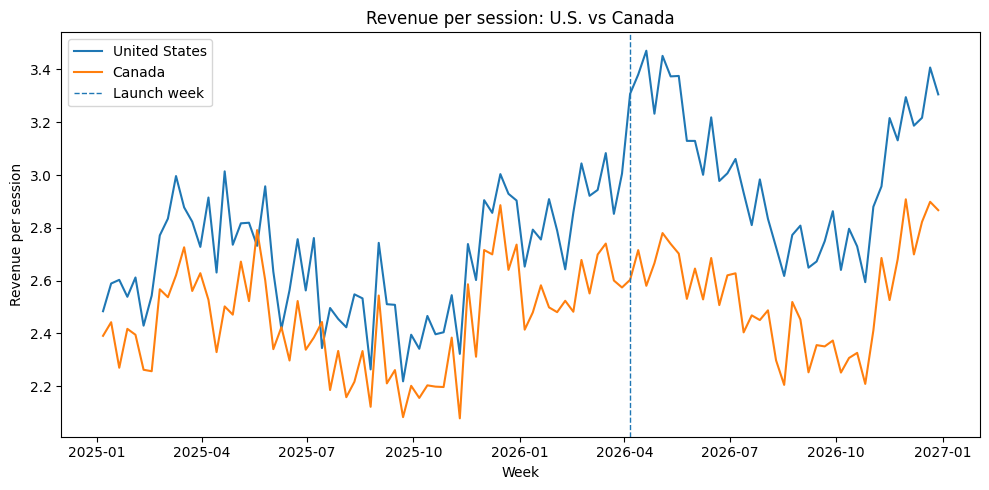

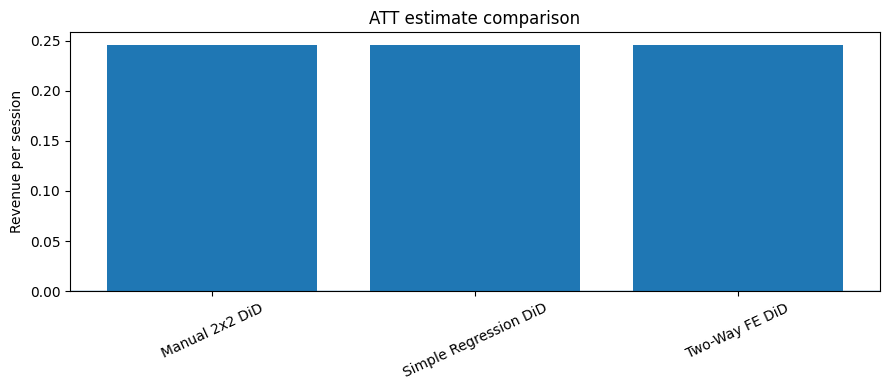

Saved figures to /mnt/data/ELC_Progressive_M1_to_M5/figures


In [21]:
try:
    import matplotlib.pyplot as plt

    fig, ax = plt.subplots(figsize=(10, 5))
    for market in [TREATED, CONTROL]:
        d = us_ca[us_ca["market"].eq(market)]
        ax.plot(d["week_start"], d[METRIC], label=market)
    ax.axvline(launch_week, linestyle="--", linewidth=1, label="Launch week")
    ax.set_title("Revenue per session: U.S. vs Canada")
    ax.set_xlabel("Week")
    ax.set_ylabel("Revenue per session")
    ax.legend()
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / "m4_weekly_rps_us_canada.png", dpi=200)
    plt.show()

    fig, ax = plt.subplots(figsize=(9, 4))
    ax.bar(comparison["method"], comparison["estimate"])
    ax.axhline(0, linewidth=1)
    ax.set_title("ATT estimate comparison")
    ax.set_ylabel("Revenue per session")
    ax.tick_params(axis="x", rotation=25)
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / "m4_estimate_comparison.png", dpi=200)
    plt.show()

    print("Saved figures to", FIGURES_DIR)
except Exception as e:
    print("Skipping plots due to error:", repr(e))


## 11. Results for the Milestone 4 presentation

The values below are the corrected HC3 results, rounded for presentation.

| Specification | Estimated effect ($/session) | 95% confidence interval | p-value |
|---|---:|---|---:|
| Simple regression DiD | +0.2459 | [0.1194, 0.3725] | 0.00014 |
| Two-way fixed-effects DiD | +0.2459 | [0.1747, 0.3171] | < 0.001 |

The simple regression estimate is the coefficient on `pilot_market:post_launch`. The two-way fixed-effects estimate is the coefficient on `digital_feature_available` after controlling for market and week effects. Both use the United States and Canada only.

The naive U.S. before-and-after change of about $0.3421 per session is descriptive and should not be labeled an ATT.


## 12. Notes for presenting the regression results

The simple regression moves the manual DiD comparison into a statistical model. It produces an estimated effect of approximately $0.246 per session, with an HC3 95% confidence interval from $0.119 to $0.373. The point estimate agrees with the manual calculation, while the regression provides a measure of uncertainty.

The two-way fixed-effects model uses `digital_feature_available` to identify U.S. market-weeks after rollout. It also includes separate effects for each market and week. Its estimated treatment effect remains about $0.246 per session, with an HC3 95% confidence interval from $0.175 to $0.317.

These estimates are statistically positive under the stated model assumptions. The fixed effects account for persistent market differences and common weekly changes, but they do not automatically remove U.S.-specific launch activity. That is why Milestone 5 investigates anticipation and marketing.


## 13. Milestone 5: anticipation and marketing adjustments

The October 13 challenge slides asked us to check whether the U.S. and Canada started moving differently immediately before launch and whether concurrent marketing could affect the estimate. We therefore use three nested two-way fixed-effects specifications, all fitted with HC3 robust standard errors:

- **Model A:** digital feature availability, market effects, and week effects.
- **Model B:** Model A plus an indicator for U.S. observations in the two weeks before rollout.
- **Model C:** Model B plus paid media index and promotion intensity.

We first compare the U.S. minus Canada revenue-per-session gap during weeks -2 and -1 with the earlier pre-launch period. The three models then allow us to compare absolute treatment estimates, confidence intervals, and relative lift using a consistent U.S. pre-launch baseline.

**Reference:** Luis's October 13 presentation, *Milestone Meeting #4*, pages 3 to 6, which assign the Milestone 5 analysis.


In [22]:
# Ensure required weekly-panel inputs exist and preserve the M4 data
required_m5 = ["week_start", "market", METRIC, "weeks_from_launch", "pilot_market",
               "digital_feature_available", "paid_media_index", "promo_intensity"]
missing_m5 = sorted(set(required_m5) - set(us_ca.columns))
if missing_m5: raise ValueError(f"Milestone 5 missing columns: {missing_m5}")
assert set(us_ca.market.unique()) == {"United States", "Canada"}
assert us_ca.groupby("market").week_start.nunique().nunique() == 1, "Expected balanced weeks"
us_ca["pilot_prelaunch_window"] = (
    us_ca["pilot_market"].eq(1) & us_ca["weeks_from_launch"].between(-2, -1)
).astype(int)
print("Anticipation flagged rows:", len(us_ca.loc[us_ca.pilot_prelaunch_window.eq(1)]))
assert us_ca.pilot_prelaunch_window.sum() == 2
assert us_ca.loc[us_ca.pilot_prelaunch_window.eq(1), "market"].eq(TREATED).all()
assert us_ca.loc[us_ca.pilot_prelaunch_window.eq(1), "weeks_from_launch"].tolist() == [-2, -1]


Anticipation flagged rows: 2


## 14. Investigate the proposed two-week anticipation window

For each pre-launch week calculate **US RPS minus Canada RPS**. Compare weeks **-2 and -1** against earlier pre-launch weeks. A larger late gap is *suggestive*, not proof of customer anticipation; it could also reflect noise or marketing.

In [23]:
# Aligned US minus Canada gaps; week -2/-1 compared to earlier pre-launch weeks
pre_us_ca = us_ca.loc[us_ca.weeks_from_launch.lt(0)].copy()
wide_pre = pre_us_ca.pivot(index="weeks_from_launch", columns="market", values=METRIC).sort_index()
wide_pre["us_minus_canada_gap"] = wide_pre[TREATED] - wide_pre[CONTROL]
base_weeks = wide_pre.loc[wide_pre.index <= -3, "us_minus_canada_gap"]
anticipation_weeks = wide_pre.loc[wide_pre.index.isin([-2, -1]), "us_minus_canada_gap"]
anticipation_comparison = pd.DataFrame([
    {"window":"Earlier pre-launch (<= -3)", "n_weeks":len(base_weeks), "mean_us_ca_gap":base_weeks.mean(), "gap_std":base_weeks.std()},
    {"window":"Anticipation (-2, -1)", "n_weeks":len(anticipation_weeks), "mean_us_ca_gap":anticipation_weeks.mean(), "gap_std":anticipation_weeks.std()},
])
late_minus_earlier = float(anticipation_weeks.mean()-base_weeks.mean())
print("Anticipation gap change (last 2 weeks minus earlier):",round(late_minus_earlier,6))
display(wide_pre.loc[[-6,-5,-4,-3,-2,-1], [TREATED,CONTROL,"us_minus_canada_gap"]])
display(anticipation_comparison)
anticipation_comparison.to_csv(RESULTS_DIR / "m5_anticipation_gap_check.csv",index=False)


Anticipation gap change (last 2 weeks minus earlier): 0.110459


market,United States,Canada,us_minus_canada_gap
weeks_from_launch,,,
-6,3.0442,2.6785,0.3657
-5,2.9215,2.5514,0.3701
-4,2.9437,2.6991,0.2446
-3,3.0833,2.7405,0.3428
-2,2.8532,2.6005,0.2527
-1,3.0053,2.5742,0.4311


,window,n_weeks,mean_us_ca_gap,gap_std
0,Earlier pre-launch (<= -3),63,0.231441,0.110266
1,"Anticipation (-2, -1)",2,0.341900,0.126148


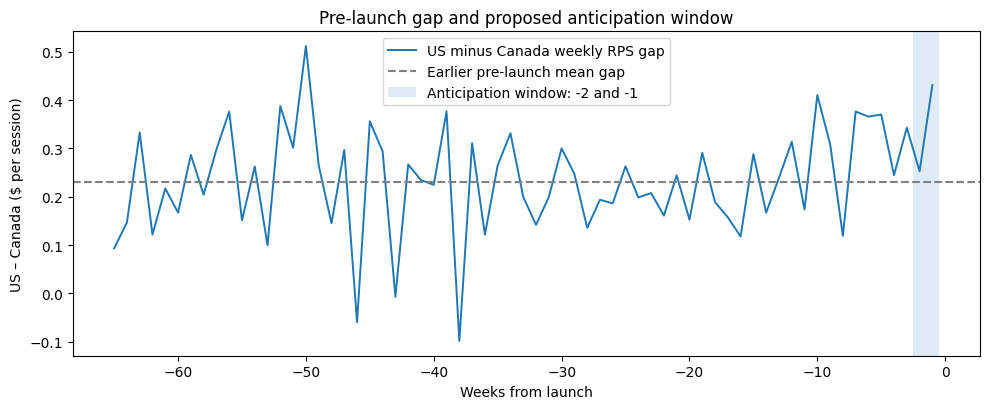

In [24]:
import matplotlib.pyplot as plt
fig,ax = plt.subplots(figsize=(10,4.2))
ax.plot(wide_pre.index,wide_pre.us_minus_canada_gap,linewidth=1.4,label="US minus Canada weekly RPS gap")
ax.axhline(base_weeks.mean(), color="gray",linestyle="--",label="Earlier pre-launch mean gap")
ax.axvspan(-2.5,-0.5,alpha=.14,label="Anticipation window: -2 and -1")
ax.set(xlabel="Weeks from launch", ylabel="US - Canada ($ per session)", title="Pre-launch gap and proposed anticipation window")
ax.legend();fig.tight_layout()
fig.savefig(FIGURES_DIR / "m5_anticipation_us_canada_gap.png",dpi=170)
plt.show()

## 15. Estimating Models A, B, and C

All three models use the same U.S. and Canada panel, so differences in the treatment coefficient reflect changes in the included controls rather than changes in the underlying sample. The treatment term is `digital_feature_available` in every specification.

We use HC3 covariance estimates for the standard errors, confidence intervals, and p-values, as directed by the challenge advisor. HC3 does not correct for correlation between nearby weeks, so the resulting inference should be interpreted with that limitation in mind.


In [25]:
# Incrementally add anticipation and marketing to two-way FE
m5_formulas = {
    "A_baseline_FE": f"{METRIC} ~ digital_feature_available + C(market) + C(week_start)",
    "B_FE_anticipation": f"{METRIC} ~ digital_feature_available + pilot_prelaunch_window + C(market) + C(week_start)",
    "C_FE_anticipation_marketing": f"{METRIC} ~ digital_feature_available + pilot_prelaunch_window + paid_media_index + promo_intensity + C(market) + C(week_start)",
}
models_m5 = {name: smf.ols(formula,data=us_ca).fit(cov_type="HC3")
             for name,formula in m5_formulas.items()}
pre_us_mean = float(us_ca.loc[(us_ca.market == TREATED) & us_ca.post_launch.eq(0),METRIC].mean())
rows_m5=[]
for name, fit in models_m5.items():
    term = "digital_feature_available"
    lo,hi = fit.conf_int().loc[term]
    att = float(fit.params[term])
    rows_m5.append({
        "model":name,"cov_type":"HC3","n_obs":int(fit.nobs),
        "att_usd_per_session":att,"relative_lift_pct_vs_us_pre":100*att/pre_us_mean,
        "std_err":float(fit.bse[term]),"ci_low":float(lo),"ci_high":float(hi),
        "p_value":float(fit.pvalues[term]),"r_squared":float(fit.rsquared),
        "anticipation_coefficient":float(fit.params.get("pilot_prelaunch_window",np.nan)),
        "paid_media_coefficient":float(fit.params.get("paid_media_index",np.nan)),
        "promo_coefficient":float(fit.params.get("promo_intensity",np.nan)),
    })
m5_comparison = pd.DataFrame(rows_m5)
m5_comparison["change_vs_A_usd"] = m5_comparison.att_usd_per_session - m5_comparison.att_usd_per_session.iloc[0]
m5_comparison["change_from_previous_usd"] = m5_comparison.att_usd_per_session.diff().fillna(0.0)
assert all(f.cov_type=="HC3" for f in models_m5.values())
assert m5_comparison.n_obs.nunique()==1
assert abs(m5_comparison.iloc[0].att_usd_per_session-fe_result["estimate"])<1e-9
display(m5_comparison)
m5_comparison.to_csv(RESULTS_DIR / "m5_three_specifications_hc3.csv",index=False)


,model,cov_type,n_obs,att_usd_per_session,relative_lift_pct_vs_us_pre,std_err,ci_low,ci_high,p_value,r_squared,anticipation_coefficient,paid_media_coefficient,promo_coefficient,change_vs_A_usd,change_from_previous_usd
0,A_baseline_FE,HC3,208,0.245914,9.172715,0.036323,0.174722,0.317106,1.286151e-11,0.959628,NaN,NaN,NaN,0.000000,0.000000
1,B_FE_anticipation,HC3,208,0.249313,9.299489,0.036389,0.177991,0.320634,7.319396e-12,0.960279,0.110459,NaN,NaN,0.003399,0.003399
2,C_FE_anticipation_marketing,HC3,208,0.209326,7.807957,0.033336,0.143989,0.274662,3.399968e-10,0.970545,0.007718,0.004146,1.161818,-0.036588,-0.039987


## 16. Comparing the specifications

Adding the anticipation indicator allows the U.S. to have a separate shift in the two weeks immediately before launch. It helps us assess the sensitivity of the estimated post-launch effect, but a change in the coefficient is not proof that customers anticipated the launch.

Adding paid media and promotion intensity addresses two measured activities that may have changed around rollout. If advertising and promotions were themselves affected by the feature or influenced by the same demand conditions, their coefficients should not be interpreted as a clean causal decomposition.

For a consistent business comparison, we calculate relative lift by dividing each treatment estimate by the average U.S. revenue per session before launch. We use the same denominator for Models A, B, and C.


In [26]:
# Plain-language numerical readout computed from actual fitted estimates
for _,r in m5_comparison.iterrows():
    print(f"{r['model']}: ATT ${r['att_usd_per_session']:+.4f}/session "
          f"({r['relative_lift_pct_vs_us_pre']:+.2f}% of US pre-RPS); "
          f"95% HC3 CI [${r['ci_low']:.4f}, ${r['ci_high']:.4f}], "
          f"p={r['p_value']:.4g}")
print(f"Gap change, weeks -2/-1 versus earlier: ${late_minus_earlier:+.4f}/session")
print("AtoB ATT change:",round(float(m5_comparison.iloc[1].change_from_previous_usd),6))
print("BtoC ATT change:",round(float(m5_comparison.iloc[2].change_from_previous_usd),6))


A_baseline_FE: ATT $+0.2459/session (+9.17% of US pre-RPS); 95% HC3 CI [$0.1747, $0.3171], p=1.286e-11
B_FE_anticipation: ATT $+0.2493/session (+9.30% of US pre-RPS); 95% HC3 CI [$0.1780, $0.3206], p=7.319e-12
C_FE_anticipation_marketing: ATT $+0.2093/session (+7.81% of US pre-RPS); 95% HC3 CI [$0.1440, $0.2747], p=3.4e-10
Gap change, weeks -2/-1 versus earlier: $+0.1105/session
A→B ATT change: 0.003399
B→C ATT change: -0.039987


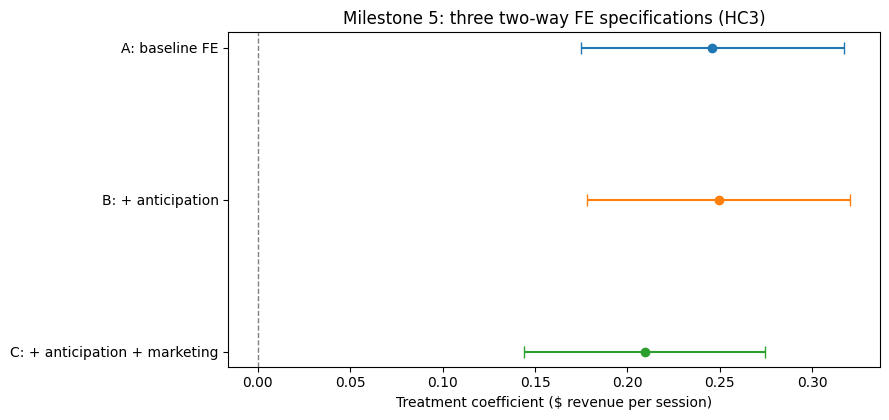

In [27]:
# Three-specification point estimates with 95% HC3 CIs
fig, ax = plt.subplots(figsize=(9,4.3))
labels=["A: baseline FE","B: + anticipation","C: + anticipation + marketing"]
for i,(_,r) in enumerate(m5_comparison.iterrows()):
    ax.errorbar(r.att_usd_per_session,i,xerr=[[r.att_usd_per_session-r.ci_low],[r.ci_high-r.att_usd_per_session]],fmt="o",capsize=4)
ax.axvline(0,color="gray",ls="--",lw=1)
ax.set_yticks(range(3),labels);ax.invert_yaxis()
ax.set(xlabel="Treatment coefficient ($ revenue per session)", title="Milestone 5: three two-way FE specifications (HC3)")
fig.tight_layout();fig.savefig(FIGURES_DIR/"m5_models_abc_hc3_confidence_intervals.png",dpi=170);plt.show()

## 17. Optional sensitivity: drop the two anticipation weeks

For transparency we also drop weeks -2/-1 from **both** markets and re-fit Model A with HC3. The advisor prefers the indicator approach in Model B; this is not a replacement for Models A/B/C.

In [28]:
drop_two = us_ca.loc[~us_ca.weeks_from_launch.isin([-2,-1])].copy()
drop_model = smf.ols(m5_formulas["A_baseline_FE"],data=drop_two).fit(cov_type="HC3")
drop_ci=drop_model.conf_int().loc["digital_feature_available"]
drop_result = pd.DataFrame([{"model":"A_exclude_both_markets_last_2_weeks",
    "att_usd_per_session":float(drop_model.params["digital_feature_available"]),
    "ci_low":float(drop_ci[0]),"ci_high":float(drop_ci[1]),
    "n_obs":int(drop_model.nobs),"cov_type":"HC3"}])
display(drop_result)
drop_result.to_csv(RESULTS_DIR/"m5_optional_anticipation_exclusion.csv",index=False)

,model,att_usd_per_session,ci_low,ci_high,n_obs,cov_type
0,A_exclude_both_markets_last_2_weeks,0.249313,0.177991,0.320634,204,HC3


## 18. Findings and limitations

The anticipation analysis compares the U.S. and Canada immediately before launch with their earlier pre-launch pattern. The regression comparison shows how the estimated treatment effect changes when we first account for that window and then add the measured marketing variables.

The fully adjusted model is useful for understanding the relationship between the feature and revenue per session after conditioning on paid media and promotions. It does not, by itself, prove a feature-only causal effect. That conclusion would also require a credible parallel-trends assumption, no relevant unmeasured U.S.-specific shocks, and appropriate treatment of potentially endogenous controls.

Finally, the naive before-and-after estimate remains a descriptive comparison, not an ATT estimate.


In [29]:
# Save easy-to-review Markdown using computed results (not manually hard-coded numbers)
lead=abs(float(m5_comparison.iloc[1].change_from_previous_usd))
marketing=abs(float(m5_comparison.iloc[2].change_from_previous_usd))
which = "marketing controls (BtoC)" if marketing>lead else ("anticipation adjustment (AtoB)" if lead>marketing else "neither (equal shifts)")
summary_lines=["# Milestone 5 : Results (HC3)","",
 "US treated; Canada control; outcome revenue per session.",
 f"US pre-launch mean RPS: ${pre_us_mean:.4f}.",
 f"Pre-launch gap in weeks -2/-1 minus earlier weeks: ${late_minus_earlier:+.4f} per session (descriptive, not a causal test).", "",
 "| Model | ATT ($/session) | Relative lift vs US pre | 95% HC3 CI | p-value |",
 "|---|---:|---:|---|---:|"]
for _,r in m5_comparison.iterrows():
    summary_lines.append(f"| {r['model']} | {r['att_usd_per_session']:+.4f} | {r['relative_lift_pct_vs_us_pre']:+.2f}% | [{r['ci_low']:+.4f}, {r['ci_high']:+.4f}] | {r['p_value']:.3g} |")
summary_lines += ["",f"Larger absolute treatment-estimate shift: {which}.",
 "Caution: HC3 corrects heteroskedasticity, not serial correlation; marketing controls may be endogenous.",
 "The feature-only causal reading remains conditional on parallel trends, no other US-only launch shocks, and valid controls."]
(RESULTS_DIR/"m5_results_and_interpretation.md").write_text("\n".join(summary_lines),encoding="utf-8")
print("\n".join(summary_lines))

# Milestone 5 : Results (HC3)

US treated; Canada control; outcome revenue per session.
US pre-launch mean RPS: $2.6809.
Pre-launch gap in weeks -2/-1 minus earlier weeks: $+0.1105 per session (descriptive, not a causal test).

| Model | ATT ($/session) | Relative lift vs US pre | 95% HC3 CI | p-value |
|---|---:|---:|---|---:|
| A_baseline_FE | +0.2459 | +9.17% | [+0.1747, +0.3171] | 1.29e-11 |
| B_FE_anticipation | +0.2493 | +9.30% | [+0.1780, +0.3206] | 7.32e-12 |
| C_FE_anticipation_marketing | +0.2093 | +7.81% | [+0.1440, +0.2747] | 3.4e-10 |

Larger absolute treatment-estimate shift: marketing controls (B→C).
Caution: HC3 corrects heteroskedasticity, not serial correlation; marketing controls may be endogenous.
The feature-only causal reading remains conditional on parallel trends, no other US-only launch shocks, and valid controls.
